## Import Libraries

In [53]:
import pandas as pd
import numpy as np

## Load NUFROC Dataset

In [54]:
ufo = pd.read_csv('nuforc_reports.csv')

print("Original entries:", len(ufo))
print("Original columns:", len(ufo.columns))

Original entries: 88125
Original columns: 12


## Standardize Column Names

In [55]:
# Standardize column names
ufo.columns = [
    c.strip().lower().replace(" ", "_")
    for c in ufo.columns
]

ufo.columns

Index(['summary', 'city', 'state', 'date_time', 'shape', 'duration', 'stats',
       'report_link', 'text', 'posted', 'city_latitude', 'city_longitude'],
      dtype='str')

## Convert Date Time and Create Year

In [56]:
# Convert date_time to datetime
ufo['date_time'] = pd.to_datetime(
    ufo['date_time'],
    errors='coerce'
)

# Extract year
ufo['year'] = ufo['date_time'].dt.year

## Define Valid US States & Filter out Non-States

In [57]:
valid_states = [
    'AL','AK','AZ','AR','CA','CO','CT','DE','FL','GA',
    'HI','ID','IL','IN','IA','KS','KY','LA','ME','MD',
    'MA','MI','MN','MS','MO','MT','NE','NV','NH','NJ',
    'NM','NY','NC','ND','OH','OK','OR','PA','RI','SC',
    'SD','TN','TX','UT','VT','VA','WA','WV','WI','WY','DC'
]

# Identify non-U.S. or invalid state values
filtered_states = ufo[
    ~ufo['state'].isin(valid_states)
]['state'].value_counts(dropna=False)

filtered_states

state
NaN    5235
ON     1410
BC      473
AB      381
QC      195
MB      147
NB      146
NS      136
SK      127
NL       26
YT       17
PE       13
NT       10
PR        2
QB        1
Name: count, dtype: int64

## Identify to US Sightings, 2010-2019

In [58]:
# Filter to U.S. states and years 2010–2019
ufo_2010_2019 = ufo[
    (ufo['state'].isin(valid_states)) &
    (ufo['year'] >= 2010) &
    (ufo['year'] <= 2019)
].copy()

print("Entries after U.S. and year filtering:", len(ufo_2010_2019))

ufo_2010_2019['year'].value_counts().sort_index()

Entries after U.S. and year filtering: 57043


year
2010.0    4235
2011.0    5174
2012.0    7406
2013.0    7125
2014.0    8096
2015.0    6468
2016.0    5325
2017.0    4734
2018.0    3075
2019.0    5405
Name: count, dtype: int64

## Handle Missing Values

In [59]:
# Missing values by column
ufo_2010_2019.isnull().sum()

missingness = pd.DataFrame({
    'Missing Values': ufo_2010_2019.isnull().sum(),
    'Missing Percentage': (
        ufo_2010_2019.isnull().mean() * 100
    )
})

missingness

,Missing Values,Missing Percentage
summary,21,0.036814
city,76,0.133233
state,0,0.000000
date_time,0,0.000000
shape,1624,2.846975
duration,2009,3.521905
stats,31,0.054345
report_link,0,0.000000
text,48,0.084147
posted,0,0.000000


## Filter out Missing City Values

In [60]:
# Number of entries before removing missing city/latitude/longitude values
before = len(ufo_2010_2019)

# Remove rows where city, city latitude, or city longitude is null
ufo_2010_2019 = ufo_2010_2019.dropna(
    subset=['city', 'city_latitude', 'city_longitude']
).copy()

# Number of entries after removal
after = len(ufo_2010_2019)

# Calculate number and percentage removed
rows_removed = before - after
percent_removed = (rows_removed / before) * 100

print("Entries before:", before)
print("Entries removed:", rows_removed)
print("Entries after:", after)
print("Percent of rows removed:", round(percent_removed, 2), "%")

# Confirm no missing values remain
print("\nMissing city values:", ufo_2010_2019['city'].isnull().sum())
print("Missing latitude values:", ufo_2010_2019['city_latitude'].isnull().sum())
print("Missing longitude values:", ufo_2010_2019['city_longitude'].isnull().sum())

Entries before: 57043
Entries removed: 7045
Entries after: 49998
Percent of rows removed: 12.35 %

Missing city values: 0
Missing latitude values: 0
Missing longitude values: 0


## Extract Month, Day, and Hour, Create Season, and Create day/night Variable

In [61]:
# Create a copy for additional preprocessing
ufo_clean = ufo_2010_2019.copy()

# Extract date/time components
ufo_clean['month'] = ufo_clean['date_time'].dt.month
ufo_clean['day'] = ufo_clean['date_time'].dt.day
ufo_clean['hour'] = ufo_clean['date_time'].dt.hour

def get_season(month):
    if month in [12, 1, 2]:
        return 'winter'
    elif month in [3, 4, 5]:
        return 'spring'
    elif month in [6, 7, 8]:
        return 'summer'
    else:
        return 'fall'

ufo_clean['season'] = ufo_clean['month'].apply(get_season)

ufo_clean['season'].value_counts()

# 1 = nighttime, 0 = daytime
ufo_clean['is_night'] = ufo_clean['hour'].apply(
    lambda h: 1 if (h >= 18 or h < 6) else 0
)

## Group Uncommon Shapes

In [62]:
common_shapes = [
    'light',
    'circle',
    'triangle',
    'disk',
    'sphere',
    'fireball'
]

ufo_clean['shape_clean'] = np.where(
    ufo_clean['shape'].isin(common_shapes),
    ufo_clean['shape'],
    'unknown'
)

ufo_clean['shape_clean'].value_counts()

shape_clean
unknown     18814
light       10727
circle       6131
fireball     4790
triangle     4278
sphere       3475
disk         1783
Name: count, dtype: int64

## Extract Duration in Seconds

In [63]:
ufo_clean['duration_sec'] = (
    ufo_clean['duration']
    .str.extract(
        r'(\d+\.?\d*)',
        expand=False
    )
    .astype(float)
)

ufo_clean['duration_log'] = np.log1p(
    ufo_clean['duration_sec']
)

In [64]:
print("Final entries:", len(ufo_clean))
print("Final columns:", len(ufo_clean.columns))
ufo_clean.head()

Final entries: 49998
Final columns: 21


,summary,city,state,date_time,shape,duration,stats,report_link,text,posted,...,city_longitude,year,month,day,hour,season,is_night,shape_clean,duration_sec,duration_log
0,My wife was driving southeast on a fairly popu...,Chester,VA,2019-12-12 18:43:00,light,5 seconds,Occurred : 12/12/2019 18:43 (Entered as : 12/...,http://www.nuforc.org/webreports/151/S151739.html,My wife was driving southeast on a fairly popu...,2019-12-22T00:00:00,...,-77.408582,2019.0,12,12,18,winter,1,light,5.0,1.791759
1,I think that I may caught a UFO on the NBC Nig...,Rocky Hill,CT,2019-03-22 18:30:00,circle,3-5 seconds,Occurred : 3/22/2019 18:30 (Entered as : 03/2...,http://www.nuforc.org/webreports/145/S145297.html,I think that I may caught a UFO on the NBC Nig...,2019-03-29T00:00:00,...,-72.639300,2019.0,3,22,18,spring,1,circle,3.0,1.386294
5,"The object has flashing lights that are green,...",Kirbyville,TX,2019-04-02 20:25:00,disk,15 minutes,Occurred : 4/2/2019 20:25 (Entered as : 04/02...,http://www.nuforc.org/webreports/145/S145476.html,"The object has flashing lights that are green,...",2019-04-08T00:00:00,...,-94.005200,2019.0,4,2,20,spring,1,disk,15.0,2.772589
6,Description is the same as Washington DC event...,Tucson,AZ,2019-05-01 11:00:00,unknown,5 minutes,Occurred : 5/1/2019 11:00 (Entered as : 5/1/1...,http://www.nuforc.org/webreports/145/S145947.html,"Description is the same as Washington, DC, eve...",2019-05-09T00:00:00,...,-110.927542,2019.0,5,1,11,spring,0,unknown,5.0,1.791759
7,Apr. 10th we witnessed a very bright silvery r...,Gold Canyon,AZ,2019-04-10 17:00:00,circle,10 minutes,Occurred : 4/10/2019 17:00 (Entered as : 04/1...,http://www.nuforc.org/webreports/145/S145766.html,Apr. 10th we witnessed a very bright silvery r...,2019-04-25T00:00:00,...,-111.436900,2019.0,4,10,17,spring,0,circle,10.0,2.397895


### Geofence Reaffirmation Using Coords

Remaining UFO sightings: 49994
Minimum latitude: 19.0676
Maximum longitude: -67.0155


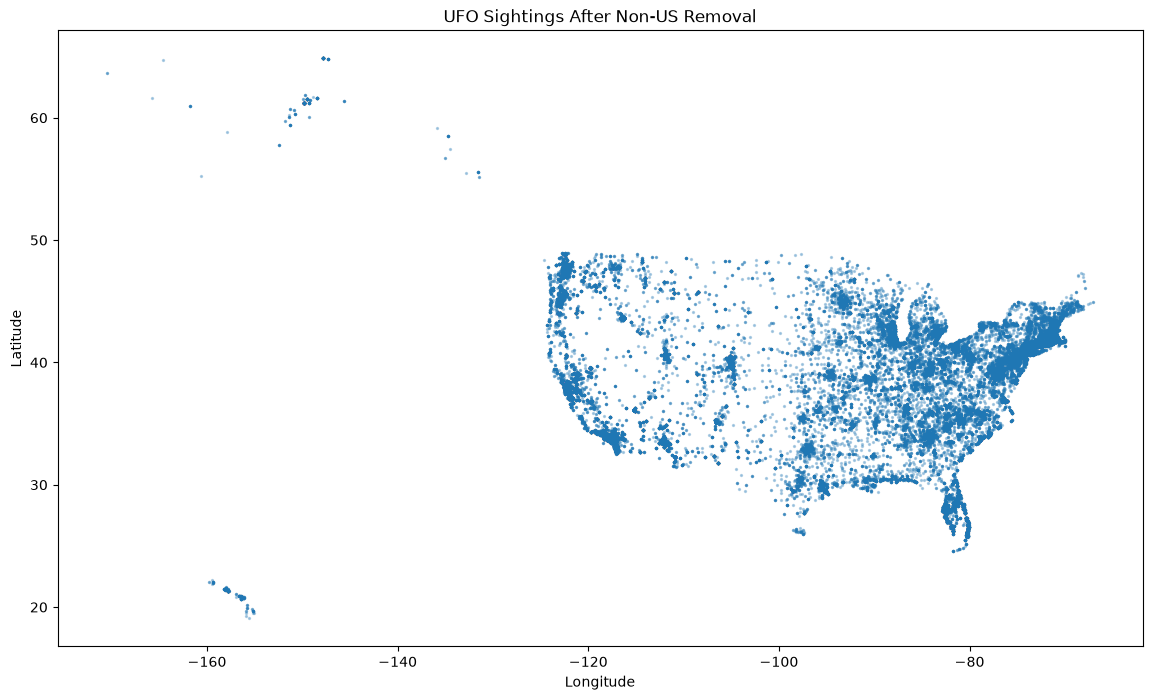

In [65]:
# Remove sightings south of Hawaii's southernmost point
# and east of the easternmost point of the 50 U.S. states

ufo_clean = ufo_clean[
    (ufo_clean['city_latitude'] >= 18.9) &
    (ufo_clean['city_longitude'] <= -66.9)
].copy()

print("Remaining UFO sightings:", len(ufo_clean))
print("Minimum latitude:", ufo_clean['city_latitude'].min())
print("Maximum longitude:", ufo_clean['city_longitude'].max())

plt.figure(figsize=(14, 8))

plt.scatter(
    ufo_clean['city_longitude'],
    ufo_clean['city_latitude'],
    s=2,
    alpha=0.3
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('UFO Sightings After Non-US Removal')

plt.show()

In [66]:
ufo_clean.to_csv(
    'ufo_2010_2019_cleaned.csv',
    index=False
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.
